# 39 — SMALL e MEDIUM: os modelos generalizam? O que falta? Data augmentation ajuda?

**Pergunta.** SMALL e MEDIUM são as classes que mais derrubam o SP. Os modelos aprendem padrões dessas classes que valem para navios novos? Se não, o que falta, e técnicas de *data augmentation* resolvem?

**Resumo das respostas** (detalhes e números nas seções):
1. **Inventário (seção 1).** SMALL e MEDIUM têm 87 e 82 navios, mas as gravações se concentram tanto que equivalem a só **12,0 e 12,6 navios** igualmente gravados (LARGE: 214). No split do artigo, **86% das SMALL e 84% das MEDIUM de teste são de um navio que já está no treino**.
2. **Generalização (seção 2).** Com navios nunca vistos, MEDIUM cai para 28–34% (acaso: 25%). SMALL cai menos, para 47–50%.
3. **O que falta (seção 3).** Navios. O recall em navios novos sobe ~14 (SMALL) e ~11 (MEDIUM) pontos a cada vez que o número de navios dobra, sem estabilizar; com o mesmo número de navios, SMALL acerta tanto quanto LARGE.
4. **Data augmentation (seções 4–6).** Testei 7 variantes, inclusive misturar gravações reais de mar sem navio ao áudio. **Nenhuma melhorou** a acurácia em navios novos, **nem no MLP, nem em RF, SVM ou BiGRU** (seção 7).
5. **Muitas gravações do mesmo navio não ajudam (seções 8–10).** MEDIUM é decorado quando o navio está no treino e não passa para navios novos; as lanchas de prático são erradas em ~45% das gravações mesmo conhecidas, quando o som acima de 250 Hz está fraco; e a confusão SMALL × MEDIUM não se concentra perto da fronteira de 50 m.

## Glossário rápido

- **Split por gravação (artigo):** as gravações são divididas entre treino e teste, mas o *mesmo navio* pode ter gravações nos dois lados. O modelo pode acertar por reconhecer o navio.
- **Split por navio:** nenhum navio aparece no treino e no teste ao mesmo tempo. Mede o que importa na prática: acertar navios que o modelo nunca ouviu. É usado em todo este notebook a partir da seção 2 (folds do NB29, `reports/split_navio/folds.csv`).
- **Recall de uma classe:** % das gravações daquela classe que o modelo acerta.
- **Acurácia balanceada (ACC):** média dos recalls das 4 classes. É a métrica principal aqui, porque com split por navio o SP pode zerar num fold em que uma classe tem recall 0.
- **Valor-p (teste F 5x2cv, Alpaydin 1999):** chance de ver uma diferença tão grande quanto a observada **se o método não fizesse diferença nenhuma**. Abaixo de 0,05, a convenção é dizer que a diferença provavelmente é real. O teste só aceita diferenças **consistentes** entre os 10 folds: um ganho grande em poucos folds e nulo nos outros não passa. É o mesmo teste do artigo do IARA (`iara_results.f_test_5x2`).

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
try:
    from IPython.display import display
except ImportError:
    display = print
for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 1); pd.set_option('display.width', 200)
PROC = os.path.join(R.ROOT, 'data', 'iara_processed')
CN = {0: 'SMALL', 1: 'MEDIUM', 2: 'LARGE', 3: 'BACKGROUND'}
COR = {'SMALL': '#2a78d6', 'MEDIUM': '#eb6834', 'LARGE': '#1baf7a'}

# metadados: mesma regra de classe do pipeline (SMALL < 50 m, MEDIUM 50-100 m, LARGE >= 100 m; E = BACKGROUND)
meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta = meta[meta.Dataset.isin(list('ABCDE'))].copy()
meta.index = meta.ID.astype(int); meta['Ship ID'] = meta['Ship ID'].str.strip()
meta['Length'] = pd.to_numeric(meta.Length, errors='coerce')
meta['Target'] = np.select([meta.Length < 50, meta.Length < 100, meta.Length >= 100], [0, 1, 2], default=3)
meta.loc[meta.Dataset == 'E', 'Target'] = 3
meta['Classe'] = meta.Target.map(CN)
meta['Recording time'] = pd.to_numeric(meta['Recording time'], errors='coerce')

def tipo(r):
    t = r['DETAILED TYPE']
    if r.Target == 0: return {'Pilot Vessel': 'Prático', 'Tug': 'Rebocador', 'Fishing Vessel': 'Pesca'}.get(t, 'Outros')
    if r.Target == 1: return {'Motor Hopper': 'Motor Hopper', 'Offshore Supply Ship': 'OSS'}.get(t, 'Outros supply/AHTS')
    return '-'
meta['Tipo'] = meta.apply(tipo, axis=1)

FOLDS = pd.read_csv(os.path.join(R.ROOT, 'reports', 'split_navio', 'folds.csv'), dtype={'Ship ID': str})
print(f"{len(meta)} gravações (A-E); folds: {FOLDS.condicao.unique().tolist()}")

1706 gravações (A-E); folds: ['split_id', 'split_navio']


## 0. Como as gravações de navio foram selecionadas: CPA e distância

**CPA** (*Closest Point of Approach*) é o **ponto da rota do navio que fica mais perto do hidrofone**, e também o instante em que o navio passa por ele. O CPA **não é o hidrofone**: o hidrofone fica parado no fundo, e o navio se move. Por isso a distância **muda ao longo da gravação**: o navio se aproxima, passa pelo CPA (distância mínima) e se afasta; o som costuma ser mais forte perto do CPA. Cada passagem tem o seu CPA: um navio passa a 80 m, outro a 400 m.

**Como o IARA escolheu as gravações de navio** dos observatórios fixos (pelo AIS, segundo o artigo do dataset):
- **Raio de inclusão, medido até o hidrofone:** subconjuntos **A e B** = navio a até 250 m; **C e D** = navio entre 250 e 500 m.
- **Tem ou não o CPA:** em **A e C** a gravação inclui o momento em que o navio passa mais perto; em **B e D** ela foi cortada antes ou depois desse momento (quando outro navio entraria a menos de 2 km), e o navio aparece só se aproximando ou só se afastando.
- **Exclusão:** nenhum **outro** navio a menos de 2 km.
- **BACKGROUND (E):** nenhum navio a menos de 10 km.

**Consequências:**
- Um navio que passou a 300 m do hidrofone nunca entrou no círculo de 250 m: vai para **C ou D**, nunca para B. O B não é "passou mais longe"; é "passou perto, mas a gravação não pegou o instante mais próximo".
- Um navio que passou a 1 km **não entra em nenhum subconjunto** (nem no BACKGROUND, que exige nenhum navio a menos de 10 km). Passagens distantes só existem nos dados de *glider* (F e G, inclusão até 10 km), que não usamos. **Todas as gravações de navio deste estudo são de passagens a até 500 m.**
- O IARA **não informa a distância exata** (só a faixa do subconjunto) nem qual observatório gravou cada arquivo. Sem a distância, um barco pequeno passando perto e um navio maior passando longe podem chegar ao hidrofone com intensidade parecida.

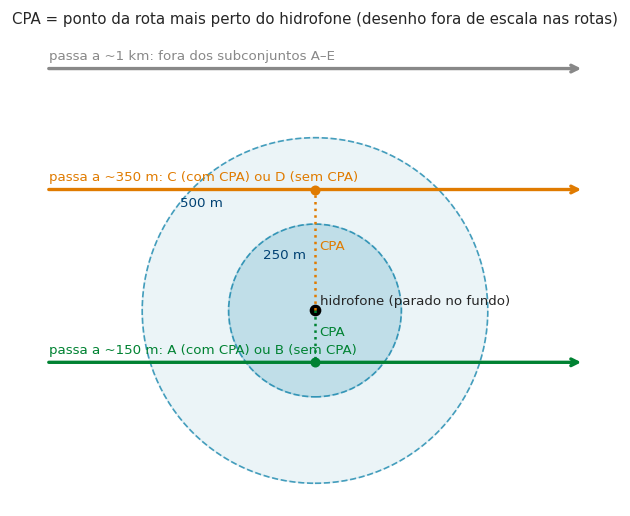

Classe,raio de inclusão,tem o CPA?,SMALL,MEDIUM,LARGE,BACKGROUND
Dataset,,,,,,
A,até 250 m,sim,113,120,223,0
B,até 250 m,não,90,73,36,0
C,250–500 m,sim,104,75,162,0
D,250–500 m,não,169,129,151,0
E,nenhum navio a menos de 10 km,–,0,0,0,261


In [2]:
# Seção 0: como as gravações de navio foram selecionadas (CPA e raio de inclusão) e quantas há em cada subconjunto
from matplotlib.patches import Circle
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.add_patch(Circle((0, 0), 500, color='#017ba5', alpha=.08)); ax.add_patch(Circle((0, 0), 250, color='#017ba5', alpha=.18))
for r in (250, 500):
    ax.add_patch(Circle((0, 0), r, fill=False, ls='--', color='#017ba5', alpha=.7))
ax.text(-150, 150, '250 m', fontsize=8, color='#004173'); ax.text(-390, 300, '500 m', fontsize=8, color='#004173')
ax.plot(0, 0, 'ko', ms=6); ax.text(15, 15, 'hidrofone (parado no fundo)', fontsize=8)
rotas = [(-150, '#008232', 'passa a ~150 m: A (com CPA) ou B (sem CPA)'),
         (350, '#e07b00', 'passa a ~350 m: C (com CPA) ou D (sem CPA)'),
         (700, '#888888', 'passa a ~1 km: fora dos subconjuntos A–E')]
for y, c, t in rotas:
    ax.annotate('', xy=(780, y), xytext=(-780, y), arrowprops=dict(arrowstyle='->', color=c, lw=2))
    ax.text(-770, y + 25, t, fontsize=8, color=c)
    if abs(y) <= 500:
        ax.plot(0, y, 'o', color=c, ms=5); ax.plot([0, 0], [0, y], ':', color=c)
        ax.text(12, y / 2, 'CPA', fontsize=8, color=c)
ax.set_xlim(-800, 800); ax.set_ylim(-560, 800); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('CPA = ponto da rota mais perto do hidrofone (desenho fora de escala nas rotas)', fontsize=9)
plt.tight_layout(); plt.show()

SUBC = pd.crosstab(meta.Dataset, meta.Classe)[['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND']]
SUBC.insert(0, 'tem o CPA?', SUBC.index.map({'A': 'sim', 'B': 'não', 'C': 'sim', 'D': 'não', 'E': '–'}))
SUBC.insert(0, 'raio de inclusão', SUBC.index.map({'A': 'até 250 m', 'B': 'até 250 m', 'C': '250–500 m', 'D': '250–500 m',
                                                  'E': 'nenhum navio a menos de 10 km'}))
display(SUBC)

## 1. Inventário: quantos navios, quantas gravações

,SMALL,MEDIUM,LARGE
gravações,476,397,572
horas,36.9,29.9,44.2
navios,87,82,417
nº efetivo de navios,12.0,12.6,213.6
navios com 1 gravação,40,40,331
navios com >10 gravações,6,7,2
% grav. em navios >10,62.0,53.9,6.3
navio mais gravado,PILOT 14 (87),HANG BO 2003 (79),PEARL RIVER (19)
% do mais gravado,18.3,19.9,3.3
comprimento mediano (m),24.0,80.0,229.0


gravações  navios  % das gravações da classe
Classe Tipo                                                            
SMALL  Prático                   321      15                       67.4
       Rebocador                  87      34                       18.3
       Outros                     35      16                        7.4
       Pesca                      33      22                        6.9
MEDIUM Motor Hopper              147       3                       37.0
       OSS                       139      46                       35.0
       Outros supply/AHTS        111      33                       28.0

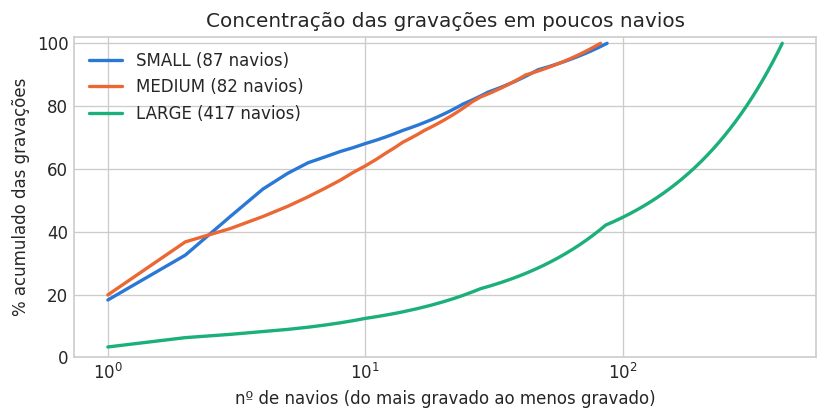

In [3]:
linhas, INV = [], {}
fid = FOLDS[FOLDS.condicao == 'split_id']
for c in [0, 1, 2]:
    d = meta[meta.Target == c]
    n = d.groupby('Ship ID').size().sort_values(ascending=False)
    p = n / n.sum()
    top = d[d['Ship ID'] == n.index[0]].Name.iloc[0]
    viu = []
    for k in range(10):
        dk = fid[fid.fold == k]
        tr = set(dk[dk.Subset == 'trn']['Ship ID'])
        te = dk[(dk.Subset == 'test') & (dk.Target == c)]
        viu.append(te['Ship ID'].isin(tr).mean() * 100)
    INV[CN[c]] = {'gravações': len(d), 'horas': d['Recording time'].sum() / 3600, 'navios': len(n),
                  'nº efetivo de navios': 1 / (p ** 2).sum(), 'navios com 1 gravação': int((n == 1).sum()),
                  'navios com >10 gravações': int((n > 10).sum()), '% grav. em navios >10': n[n > 10].sum() / len(d) * 100,
                  'navio mais gravado': f'{top} ({n.iloc[0]})', '% do mais gravado': n.iloc[0] / len(d) * 100,
                  'comprimento mediano (m)': d.groupby('Ship ID').Length.first().median(),
                  '% com CPA (A/C)': d.Dataset.isin(['A', 'C']).mean() * 100,
                  '% teste com navio no treino (split do artigo)': np.mean(viu)}
INV = pd.DataFrame(INV)
display(INV)

TIPOS = (meta[meta.Target < 2].groupby(['Classe', 'Tipo'])
         .agg(gravações=('Name', 'size'), navios=('Ship ID', 'nunique')).reset_index())
TIPOS['% das gravações da classe'] = TIPOS.gravações / TIPOS.groupby('Classe').gravações.transform('sum') * 100
display(TIPOS.sort_values(['Classe', 'gravações'], ascending=[False, False]).set_index(['Classe', 'Tipo']))
PILOT5 = meta[(meta.Target == 0)].groupby('Ship ID').size().sort_values(ascending=False).iloc[:5].sum() / (meta.Target == 0).sum() * 100
HB2 = meta[(meta.Target == 1)].groupby('Ship ID').size().sort_values(ascending=False).iloc[:2].sum() / (meta.Target == 1).sum() * 100

fig, ax = plt.subplots(figsize=(7, 3.6))
for c in [0, 1, 2]:
    n = meta[meta.Target == c].groupby('Ship ID').size().sort_values(ascending=False).values
    ax.plot(np.arange(1, len(n) + 1), np.cumsum(n) / n.sum() * 100, lw=2, color=COR[CN[c]], label=f'{CN[c]} ({len(n)} navios)')
ax.set_xscale('log'); ax.set_xlabel('nº de navios (do mais gravado ao menos gravado)'); ax.set_ylabel('% acumulado das gravações')
ax.set_title('Concentração das gravações em poucos navios'); ax.legend(); ax.set_ylim(0, 102)
plt.tight_layout(); plt.show()

**Leitura.**
- **Poucos navios dominam as classes.** Em SMALL, 5 lanchas de prático (PILOT 08–14) somam **59%** das gravações; em MEDIUM, 2 dragas irmãs (HANG BO 2002/2003) somam **37%**. Em LARGE, o navio mais gravado tem só 3% das gravações.
- **Nº efetivo de navios** (1/Σp², em que p é a fração de gravações de cada navio): quantos navios *igualmente gravados* dariam a mesma diversidade. SMALL ≈ 12,0, MEDIUM ≈ 12,6, LARGE ≈ 214.
- **SMALL é, na prática, "lancha de prático"; MEDIUM é "draga HANG BO + supply".** Rebocadores e OSS têm mais navios distintos, mas poucas gravações cada.
- **Distância e CPA são parecidos nas duas classes** (46% e 49% das gravações com CPA) e não explicam a confusão (seção 2).

## 2. Os modelos generalizam? Split por gravação × split por navio

In [4]:
MODELOS = {'MLP LOFAR': 'mlp_lofar', 'SVM MEL': 'svm2000_mel', 'BiGRU LOFAR': 'bigru_lofar'}
rows = []
for nome, e in MODELOS.items():
    for cond, rot in [('split_id', 'por gravação (artigo)'), ('split_navio', 'por navio')]:
        s = R.summary(f'{cond}_{e}_4c')
        rows.append({'modelo': nome, 'split': rot, **{k: s[k][0] for k in ['SP', 'ACC', 'R_SMALL', 'R_MEDIUM', 'R_LARGE', 'R_BACKGROUND']}})
GEN = pd.DataFrame(rows).set_index(['modelo', 'split'])
display(GEN)

def por_arquivo(exp):
    d = pd.concat(R.file_predictions(exp).values()); d['File'] = d.File.astype(int)
    d = d.join(meta[['Tipo', 'Dataset']], on='File'); d['ok'] = d.Target == d.Prediction
    return d

TIPO_REC = {}
for nome, e in MODELOS.items():
    for cond in ['split_id', 'split_navio']:
        d = por_arquivo(f'{cond}_{e}_4c'); d = d[d.Target < 2]
        TIPO_REC[(nome, cond)] = d.groupby(['Target', 'Tipo']).ok.mean() * 100
TIPO_REC = pd.DataFrame(TIPO_REC)
TIPO_REC.index = TIPO_REC.index.set_levels([[CN[i] for i in TIPO_REC.index.levels[0]], TIPO_REC.index.levels[1]])
print('Recall (%) por tipo de navio:'); display(TIPO_REC.round(0))

d = por_arquivo('split_navio_mlp_lofar_4c')
SUB = d[d.Target < 2].groupby(['Target', 'Dataset']).ok.mean().mul(100).unstack().rename(index=CN)
print('Recall (%) por subconjunto, MLP LOFAR com split por navio:'); display(SUB.round(0))
DEST = {}
for nome, e in MODELOS.items():
    d = por_arquivo(f'split_navio_{e}_4c')
    for c in [0, 1]:
        x = d[(d.Target == c) & ~d.ok].Prediction.map(CN).value_counts(normalize=True) * 100
        DEST[(nome, CN[c])] = x
DEST = pd.DataFrame(DEST).fillna(0)
print('Para onde vão os erros (% dos erros), split por navio:'); display(DEST.round(0))

SP   ACC  R_SMALL  R_MEDIUM  R_LARGE  R_BACKGROUND
modelo      split                                                                      
MLP LOFAR   por gravação (artigo)  67.4  67.8     54.1      65.9     71.2          80.0
            por navio              56.1  58.3     49.8      34.5     67.7          81.1
SVM MEL     por gravação (artigo)  61.3  62.5     53.6      52.5     71.5          72.5
            por navio              50.5  54.0     47.0      31.4     67.0          70.3
BiGRU LOFAR por gravação (artigo)  62.5  63.0     57.5      50.5     68.1          75.8
            por navio              50.8  53.8     47.0      27.6     66.2          74.3

Recall (%) por tipo de navio:


MLP LOFAR              SVM MEL             BiGRU LOFAR            
                           split_id split_navio split_id split_navio    split_id split_navio
Target Tipo                                                                                 
SMALL  Outros                  65.0        54.0     55.0        48.0        67.0        48.0
       Pesca                   51.0        50.0     44.0        47.0        47.0        43.0
       Prático                 55.0        49.0     56.0        43.0        58.0        43.0
       Rebocador               49.0        45.0     49.0        44.0        54.0        45.0
MEDIUM Motor Hopper            89.0        36.0     78.0        27.0        81.0        27.0
       OSS                     51.0        32.0     37.0        29.0        32.0        25.0
       Outros supply/AHTS      54.0        29.0     38.0        31.0        33.0        20.0

Recall (%) por subconjunto, MLP LOFAR com split por navio:


Dataset,A,B,C,D
Target,,,,
SMALL,55.0,41.0,52.0,47.0
MEDIUM,36.0,30.0,31.0,31.0


Para onde vão os erros (% dos erros), split por navio:


MLP LOFAR        SVM MEL        BiGRU LOFAR       
               SMALL MEDIUM   SMALL MEDIUM       SMALL MEDIUM
Prediction                                                   
BACKGROUND       8.0    2.0    10.0    2.0         5.0    2.0
LARGE           47.0   23.0    45.0   33.0        56.0   32.0
MEDIUM          45.0    0.0    45.0    0.0        38.0    0.0
SMALL            0.0   75.0     0.0   65.0         0.0   66.0

**Leitura.**
- **MEDIUM não generaliza.** No MLP LOFAR, o recall cai de 65,9% para **34,5%** só por trocar a regra de divisão; nos outros modelos, a queda é parecida.
- **O MEDIUM "bom" do artigo era o Motor Hopper:** 89% de acerto no split por gravação, 36% no split por navio. O modelo reconhecia as dragas HANG BO porque a irmã estava no treino.
- **Para navios novos, MEDIUM vira SMALL:** 75% dos erros de MEDIUM do MLP LOFAR vão para SMALL.
- **SMALL generaliza pouco, mas generaliza:** 54,1% → 49,8% no MLP LOFAR, com acerto parecido nos três tipos (prático, rebocador, pesca).
- **Subconjunto (distância/CPA) quase não importa:** com split por navio, MEDIUM fica entre 30% e 36% nos quatro subconjuntos.

## 3. O que falta? Curva de aprendizado pelo número de navios

Em cada fold do split por navio, retirei do treino uma parte dos navios (ficando com 25, 50, 75 ou 100%) e medi o recall nos navios do teste, que o modelo nunca viu. Dois cenários:
- **reduzindo SMALL e MEDIUM juntos** (LARGE e BACKGROUND inteiros);
- **controle: reduzindo só LARGE**, para comparar as classes com o mesmo número de navios.

Modelo: o MLP LOFAR da base (seção 4). 10 folds × 2 sorteios por fração (`scratch/apres_small_medium/curva_navios.py`).

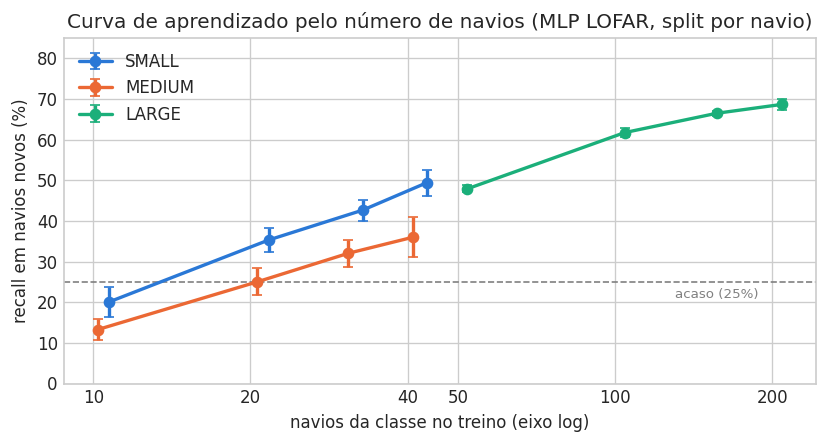

SMALL             MEDIUM              LARGE            
     navios recall   ep navios recall   ep navios recall   ep
frac                                                         
0.2    10.7   20.0  3.6   10.2   13.3  2.6   52.1   47.9  0.8
0.5    21.7   35.3  3.0   20.6   25.0  3.3  104.3   61.7  1.1
0.8    32.8   42.6  2.6   30.8   32.0  3.4  156.4   66.5  0.7
1.0    43.5   49.4  3.2   41.0   36.0  5.0  208.5   68.7  1.3

Ganho de recall por duplicação do nº de navios: {'SMALL': np.float64(14.3), 'MEDIUM': np.float64(11.4), 'LARGE': np.float64(10.6)}


In [5]:
RS = os.path.join(R.ROOT, 'reports', 'small_medium')
csm = pd.read_csv(os.path.join(RS, 'curva_navios_sm.csv')); clg = pd.read_csv(os.path.join(RS, 'curva_navios_large.csv'))
CURVA = {}
fig, ax = plt.subplots(figsize=(7, 3.8))
for cn, d, nc in [('SMALL', csm, 'n_small'), ('MEDIUM', csm, 'n_medium'), ('LARGE', clg, 'n_large')]:
    g = d.groupby('frac').agg(navios=(nc, 'mean'), recall=(f'R_{cn}', 'mean'), ep=(f'R_{cn}', 'sem'))
    CURVA[cn] = g
    ax.errorbar(g.navios, g.recall, yerr=g.ep, color=COR[cn], lw=2, marker='o', capsize=3, label=cn)
ax.axhline(25, color='gray', ls='--', lw=1); ax.text(130, 21, 'acaso (25%)', color='gray', fontsize=8)
ax.set_xscale('log'); ax.set_xticks([10, 20, 40, 50, 100, 200]); ax.set_xticklabels(['10', '20', '40', '50', '100', '200'])
ax.set_xlabel('navios da classe no treino (eixo log)'); ax.set_ylabel('recall em navios novos (%)'); ax.set_ylim(0, 85)
ax.set_title('Curva de aprendizado pelo número de navios (MLP LOFAR, split por navio)'); ax.legend()
plt.tight_layout(); plt.show()
display(pd.concat(CURVA, axis=1).round(1))
# ganho por duplicação de navios (inclinação em log2)
INCL = {cn: np.polyfit(np.log2(g.navios), g.recall, 1)[0] for cn, g in CURVA.items()}
print('Ganho de recall por duplicação do nº de navios:', {k: round(v, 1) for k, v in INCL.items()})

**Leitura.**
- **O recall cresce com o número de navios e não estabiliza.** SMALL: 20% com 11 navios → 49% com 44. MEDIUM: 13% → 36%. Cada vez que o número de navios dobra, o recall sobe ~14 pontos em SMALL e ~11 em MEDIUM.
- **Com o mesmo número de navios, SMALL acerta tanto quanto LARGE:** 49% com 44 navios SMALL × 48% com 52 navios LARGE. LARGE é "fácil" porque tem muitos navios, não porque soa mais diferente.
- **MEDIUM fica ~13 pontos abaixo de SMALL** com o mesmo número de navios: além de faltar navios, supply/AHTS soam parecidos com rebocadores (NB35–38).
- **Ressalva:** reduzir navios também reduz gravações. A curva mede "menos navios e menos gravações juntos"; o inventário (seção 1) e o peso dos navios repetidos sugerem que o fator que limita é o número de navios distintos.

## 4. Data augmentation no LOFAR

*Data augmentation* = criar versões modificadas dos exemplos de treino para o modelo aprender a ignorar o que não importa. Todas as variantes usam **o mesmo modelo, os mesmos folds e as mesmas sementes** da base; só o treino muda. O teste é sempre o LOFAR original, de navios nunca vistos (`scratch/apres_small_medium/aug_ship_split.py`).

| Variante | O que faz | O que pretende simular |
|---|---|---|
| navio | peso igual para cada navio dentro da classe (reponderação, não augmentation) | tirar o domínio das lanchas de prático e das dragas HANG BO |
| stretch | estica/comprime o eixo de frequência (fator 0,92–1,08) | o mesmo navio em outra rotação/velocidade |
| mask | apaga 2 faixas aleatórias de até ~375 Hz | não depender de uma raia específica |
| mixnavio | mistura espectros de 2 navios diferentes da mesma classe | "navios virtuais", mais diversidade |
| ruido | soma ruído gaussiano artificial ao LOFAR padronizado | variação de condição (forma simplificada) |
| navio-stretch-mask | as três juntas | — |
| bg | soma uma gravação **real** de BACKGROUND ao **áudio** e recalcula o LOFAR | o mesmo navio em outro mar (seções 5 e 6) |

**Critério de ganho real, definido antes de ver os resultados:** Δ ACC ≥ +1,5 ponto, p < 0,05 e melhora em pelo menos 8 dos 10 folds, **sem** SMALL e MEDIUM se moverem em sentidos opostos.

,ACC bal.,SMALL,MEDIUM,LARGE,BG,Δ ACC,Δ SMALL,Δ MEDIUM,erro-padrão Δ ACC,folds melhores,"p (F 5x2cv, ACC)"
variante,,,,,,,,,,,
base,58.7,49.4,36.0,68.7,80.8,NaN,NaN,NaN,NaN,NaN,NaN
navio,57.4,32.3,39.2,75.9,82.0,-1.4,-17.0,3.2,1.0,4.0,1.6e-01
stretch,58.2,42.1,41.7,62.6,86.5,-0.5,-7.3,5.7,0.6,3.0,6.0e-01
mask,57.8,32.4,45.6,71.5,81.7,-0.9,-17.0,9.6,0.5,3.0,2.3e-01
mixnavio,59.0,45.7,38.8,66.2,85.2,0.3,-3.7,2.8,0.4,8.0,6.0e-01
ruido,57.8,44.3,40.1,66.3,80.4,-0.9,-5.1,4.1,0.4,3.0,4.7e-01
navio-stretch-mask,56.0,13.8,61.5,65.3,83.3,-2.7,-35.6,25.5,0.9,2.0,2.6e-02
bg,58.2,50.0,34.9,66.8,81.3,-0.5,0.6,-1.1,0.2,2.0,5.9e-01


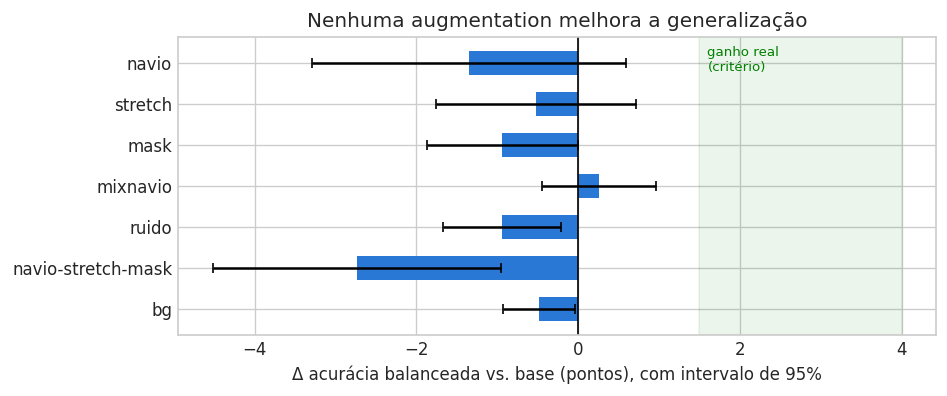

In [6]:
VARIANTES = {
    'base': 'treino normal (referência)',
    'navio': 'peso igual para cada navio dentro da classe (não é augmentation, é reponderação)',
    'stretch': 'estica/comprime o eixo de frequência por um fator entre 0,92 e 1,08 (outra rotação/velocidade)',
    'mask': 'apaga 2 faixas aleatórias de até 48 bins (~375 Hz) cada (SpecAugment em frequência)',
    'mixnavio': 'mistura o espectro de dois navios diferentes da MESMA classe ("navio virtual")',
    'ruido': 'soma ruído gaussiano artificial ao LOFAR já padronizado (sigma 0,3)',
    'navio-stretch-mask': 'navio + stretch + mask juntos',
    'bg': 'soma uma gravação REAL de BACKGROUND ao ÁUDIO e recalcula o LOFAR (secão 6)',
}
BASE = 'augnavio_mlp_lofar_base_4c'
fb = R.fold_metrics(BASE)
rows = []
for v, desc in VARIANTES.items():
    e = f'augnavio_mlp_lofar_{v}_4c'
    fm = R.fold_metrics(e)
    r = {'variante': v, 'o que faz': desc, 'ACC bal.': fm.ACC.mean(), 'SMALL': fm.R_SMALL.mean(), 'MEDIUM': fm.R_MEDIUM.mean(),
         'LARGE': fm.R_LARGE.mean(), 'BG': fm.R_BACKGROUND.mean()}
    if v != 'base':
        dd = fm.ACC - fb.ACC
        r.update({'Δ ACC': dd.mean(), 'Δ SMALL': (fm.R_SMALL - fb.R_SMALL).mean(), 'Δ MEDIUM': (fm.R_MEDIUM - fb.R_MEDIUM).mean(),
                  'erro-padrão Δ ACC': dd.std(ddof=1) / np.sqrt(len(dd)), 'folds melhores': int((dd > 0).sum()),
                  'p (F 5x2cv, ACC)': R.f_test_5x2(e, BASE, metric='ACC')[1]})
    rows.append(r)
AUG = pd.DataFrame(rows).set_index('variante')
display(AUG.drop(columns='o que faz').round({'ACC bal.': 1, 'SMALL': 1, 'MEDIUM': 1, 'LARGE': 1, 'BG': 1, 'Δ ACC': 2,
                                             'Δ SMALL': 1, 'Δ MEDIUM': 1, 'erro-padrão Δ ACC': 2, 'p (F 5x2cv, ACC)': 3}))
ORIG = R.summary('split_navio_mlp_lofar_4c')['ACC'][0]

fig, ax = plt.subplots(figsize=(8, 3.4))
a = AUG.drop(index='base')
ax.barh(a.index[::-1], a['Δ ACC'][::-1], xerr=1.96 * a['erro-padrão Δ ACC'][::-1], color='#2a78d6', height=0.6, capsize=3)
ax.axvline(0, color='k', lw=1); ax.axvspan(1.5, 4, color='green', alpha=0.08)
ax.text(1.6, len(a) - 0.6, 'ganho real\n(critério)', fontsize=8, color='green', va='top')
ax.set_xlabel('Δ acurácia balanceada vs. base (pontos), com intervalo de 95%')
ax.set_title('Nenhuma augmentation melhora a generalização')
plt.tight_layout(); plt.show()

**Leitura.**
- **Nenhuma variante atende ao critério.** A melhor é **mixnavio** (Δ ACC +0,26, p = 0,604), dentro da variação normal entre treinos (erro-padrão 0,4). A base re-rodada (ACC 58,7) reproduz a original do NB29 (58,3).
- **Armadilha: SMALL e MEDIUM se movem em sentidos opostos.** Na navio-stretch-mask, MEDIUM vai a 62% e SMALL cai a 14%; é a única com p < 0,05, e para pior (Δ ACC -2,74). O modelo só passou a responder "MEDIUM" quando tem dúvida, sem aprender a distinguir.
- **Peso por navio derruba SMALL** (32% contra 49%): o padrão das lanchas de prático generaliza entre lanchas diferentes, e é dele que vem boa parte do recall SMALL (67% das SMALL são lanchas de prático).

## 5. O modelo usa o "ambiente" da gravação como pista?

Motivação para a variante **bg**: se o modelo associa a classe ao **jeito da gravação** (mar, equipamento, local), e não ao navio, misturar fundos diferentes no treino deveria tirar essa pista.

O IARA não registra data, sessão nem hidrofone (e os WAVs não têm timestamp). Usei como **assinatura de ambiente** o espectro do **bloco de 10 s mais silencioso** de cada gravação, de **8 a 23 kHz** (`psd24k`), faixa que o LOFAR (0–8 kHz) não vê.
- **T1:** a assinatura de ambiente sozinha separa SMALL de MEDIUM em navios novos?
- **T2:** para cada gravação de teste, procuro as 10 gravações de treino com ambiente mais parecido. Se a previsão do modelo acompanha a classe desses "vizinhos de ambiente" mesmo quando ela está errada, o ambiente está influenciando a decisão.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy import stats as st

AMB = pd.read_pickle(os.path.join(PROC, 'cache_amb_min_psd24k.pkl'))   # bloco de 10 s mais silencioso, 8-23 kHz, 16 bandas (dB)
AMB = AMB.loc[AMB.index.isin(meta.index)]
print(f'Assinatura de ambiente: {AMB.shape[0]} gravações x {AMB.shape[1]} bandas ({AMB.columns[0]} ... {AMB.columns[-1]} Hz)')

# T1: a assinatura de ambiente separa SMALL de MEDIUM em navios novos?
def peso_navio(g, y):
    s = pd.Series(g); w = 1.0 / s.map(s.value_counts()).values
    for c in np.unique(y): w[y == c] /= w[y == c].sum()
    return w * len(y) / w.sum()

sm = meta.loc[AMB.index]; sm = sm[sm.Target < 2]
X, y, g = AMB.loc[sm.index].values, sm.Target.values, sm['Ship ID'].values
w = peso_navio(g, y); aucs = []
for r in range(10):
    p = np.zeros(len(y))
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=r).split(X, y, g):
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=2000))
        clf.fit(X[tr], y[tr], logisticregression__sample_weight=w[tr]); p[te] = clf.predict_proba(X[te])[:, 1]
    aucs.append(roc_auc_score(y, p, sample_weight=w))
T1_AUC = np.mean(aucs)
print(f'T1 - SMALL x MEDIUM só pela assinatura de ambiente, navios novos: AUC {T1_AUC:.2f} (acaso 0,50)')

# T2: as previsões do modelo seguem a classe dos vizinhos de ambiente no treino?
FN = FOLDS[FOLDS.condicao == 'split_navio']
def t2(exp):
    P = R.file_predictions(exp); rows = []
    for k in range(10):
        d = FN[FN.fold == k]; tr = d[(d.Subset == 'trn') & (d.Target < 3)].File.values; tr = tr[np.isin(tr, AMB.index)]
        sc = StandardScaler().fit(AMB.loc[tr]); nn = NearestNeighbors(n_neighbors=10).fit(sc.transform(AMB.loc[tr]))
        pk = P[k].copy(); pk['File'] = pk.File.astype(int); pk = pk[(pk.Target < 2) & pk.File.isin(AMB.index)]
        _, ind = nn.kneighbors(sc.transform(AMB.loc[pk.File])); ytr = meta.loc[tr, 'Target'].values
        for (_, r), nb in zip(pk.iterrows(), ind):
            v = np.bincount(ytr[nb], minlength=3) / 10
            rows.append((r.Target, r.Prediction, v[1] if r.Target == 0 else v[0]))
    T = pd.DataFrame(rows, columns=['y', 'pred', 'viz_outra']); out = {}
    for c in [0, 1]:
        t = T[T.y == c].copy(); t['tercil'] = pd.qcut(t.viz_outra.rank(method='first'), 3, labels=['poucos', 'médio', 'muitos'])
        out[CN[c]] = t.groupby('tercil', observed=True).pred.apply(lambda s: (s == c).mean() * 100)
    return pd.DataFrame(out).T

T2 = {v: t2(f'augnavio_mlp_lofar_{v}_4c') for v in ['base', 'bg']}
T2 = pd.concat(T2, names=['modelo', 'classe'])
T2['queda (poucos - muitos)'] = T2['poucos'] - T2['muitos']
print('T2 - acerto (%) por tercil de "vizinhos de ambiente da outra classe":'); display(T2.round(1))

Assinatura de ambiente: 1706 gravações x 16 bandas (8000-8545 ... 21530-23000 Hz)


T1 - SMALL x MEDIUM só pela assinatura de ambiente, navios novos: AUC 0.58 (acaso 0,50)


T2 - acerto (%) por tercil de "vizinhos de ambiente da outra classe":


tercil         poucos  médio  muitos  queda (poucos - muitos)
modelo classe                                                
base   SMALL     57.6   48.8    38.4                     19.2
       MEDIUM    39.7   35.1    26.7                     13.0
bg     SMALL     59.0   49.9    37.5                     21.5
       MEDIUM    39.7   34.6    24.6                     15.1

**Leitura.**
- **T1: o ambiente quase não indica a classe** (AUC entre 0,51 e 0,58; acaso 0,50). O valor depende da partição sorteada, que muda com a versão do scikit-learn: o mesmo código dá 0,51 (0,49–0,53) com a versão do host e 0,58 (0,56–0,60) com a do container. É um sinal fraco, bem menor que o efeito do T2.
- **T2: mas mexe na decisão do modelo base.** SMALL cujo ambiente parece o de MEDIUM do treino: acerto 38%, contra 58% quando parece o de SMALL (queda de 19 pontos). Em MEDIUM, a queda é de 13 pontos. Na análise exploratória (`teste_impressao_ambiente.py`), o efeito aparece dentro de cada tipo de navio, de cada subconjunto e até dentro do mesmo navio.
- **Com a mistura (bg), o efeito não diminui:** queda de 21 pontos em SMALL e 15 em MEDIUM. Somar mar real não tirou a sensibilidade do modelo a essa assinatura. Portanto ela **não é ruído de fundo somado**: deve refletir algo da própria gravação (distância, velocidade do navio, cadeia de gravação), que a mistura não imita.

## 6. Mistura com BACKGROUND (variante bg): como as cópias foram feitas

Para cada uma das gravações de navio (SMALL, MEDIUM **e** LARGE, para que o ruído somado não vire pista de classe), gerei 4 cópias (`scripts/extrair_lofar_mixbg.py`). Em cada cópia:
1. sorteio uma das gravações de **BACKGROUND** do IARA (subconjunto E, rotuladas pelo próprio dataset como "sem navio") e um ponto de início nela;
2. ajusto o volume do fundo para que a potência da gravação original fique entre 0 e 20 dB **acima** da potência do fundo somado. Atenção: isso **não** é a relação sinal-ruído do navio (os níveis do IARA não são calibrados, e a gravação já traz o mar daquele dia); é só a proporção entre a gravação e o fundo somado;
3. somo os dois áudios e calculo o LOFAR **exatamente** como o pipeline (sem mistura, o resultado é idêntico ao `cache_lofar.pkl`).

O LOFAR usado pelos modelos **não foi alterado**: as cópias ficam em pasta própria (`data/iara_processed/lofar_mixbg/`).

**No treino:** a cada lote, metade das janelas é trocada pela mesma janela de uma cópia sorteada (o rótulo continua o do navio). **Só valem cópias cujo fundo é uma gravação de BACKGROUND do treino daquele fold**; as outras ficam de fora para nenhum som de teste entrar no treino. O tamanho do treino e o número de passos são os mesmos da base.

In [8]:
SOR = pd.read_csv(os.path.join(PROC, 'lofar_mixbg', 'sorteios.csv'))
print(f"{len(SOR)} cópias, {SOR.ID.nunique()} gravações de navio, {SOR.bg_id.nunique()} gravações de BACKGROUND usadas como fundo")
# exemplo de uma gravação e cópias válidas por fold (só fundos do TREINO do fold)
VAL = []
for k in range(10):
    d = FN[FN.fold == k]
    bg = set(d[(d.Subset == 'trn') & (d.Target == 3)].File); tr = set(d[(d.Subset == 'trn') & (d.Target < 3)].File)
    s = SOR[SOR.ID.isin(tr)]
    VAL.append(s.assign(ok=s.bg_id.isin(bg)).groupby('ID').ok.sum().value_counts().reindex(range(5), fill_value=0))
VAL = pd.DataFrame(VAL).mean().rename('gravações de treino (média dos 10 folds)')
VAL.index.name = 'cópias válidas'
display(VAL.round(0).to_frame())
MEDIA_VAL = (VAL * VAL.index).sum() / VAL.sum()
EX_ID = int(meta[(meta.Name == 'PILOT 10')].index.min())
d0 = FN[FN.fold == 0]; bg0 = set(d0[(d0.Subset == 'trn') & (d0.Target == 3)].File)
EX = SOR[SOR.ID == EX_ID].assign(**{'fundo no treino do fold 0': lambda x: x.bg_id.isin(bg0)})
print(f'Exemplo: gravação {EX_ID} (PILOT 10)'); display(EX.round(1).set_index('copia'))

# quanto a mistura altera o LOFAR: correlação janela a janela com o original, por faixa de razão
import pickle
orig = pickle.load(open(os.path.join(PROC, 'cache_lofar.pkl'), 'rb'))
amostra = SOR.sample(400, random_state=0); sim = []
for x in amostra.itertuples():
    a = np.load(os.path.join(PROC, 'lofar_mixbg', f'{x.ID}_{x.copia}.npy')); o = orig[x.ID]
    sim.append((x.rsf_db, np.mean([np.corrcoef(a[i], o[i])[0, 1] for i in range(len(o))])))
SIM = pd.DataFrame(sim, columns=['razão (dB)', 'correlação'])
SIM = SIM.groupby(pd.cut(SIM['razão (dB)'], [0, 5, 10, 15, 20]), observed=True)['correlação'].agg(['size', 'mean'])
SIM.columns = ['cópias', 'correlação média com o original']
display(SIM.round(2))

5780 cópias, 1445 gravações de navio, 261 gravações de BACKGROUND usadas como fundo


,gravações de treino (média dos 10 folds)
cópias válidas,
0,45.0
1,174.0
2,268.0
3,188.0
4,47.0


Exemplo: gravação 2 (PILOT 10)


,ID,bg_id,offset_s,rsf_db,fundo no treino do fold 0
copia,,,,,
0,2,1455,97.0,13.3,False
1,2,1524,148.6,10.7,False
2,2,1494,51.9,8.9,True
3,2,1528,117.1,6.9,False


,cópias,correlação média com o original
razão (dB),,
"(0, 5]",94,0.7
"(5, 10]",95,0.8
"(10, 15]",105,0.9
"(15, 20]",106,0.9


**Leitura.**
- Em média, cada gravação de navio tem **2,0 cópias válidas por fold** (as outras usaram fundos que estão no teste). Algumas ficam sem nenhuma, por puro sorteio (~(1/2)⁴ ≈ 6%), e treinam só com o original.
- A mistura altera o LOFAR na medida esperada: com fundo fraco (15–20 dB abaixo), a correlação com o original fica em ~0,95; com fundo forte (0–5 dB), em ~0,71. O navio continua reconhecível.
- **Resultado (seção 4):** ACC 58,2 contra 58,7 da base (Δ -0,48, p = 0,592, melhor em 2 de 10 folds). **Sem ganho.**

## 7. A augmentation funciona melhor em outros modelos?

O MLP poderia ser o modelo "errado" para aproveitar augmentation. Repeti as variantes em **RF**, **SVM** (Nyström) e **BiGRU**, com os mesmos hiperparâmetros, folds e split por navio do NB29 (`scratch/apres_small_medium/aug_ship_split_modelos.py`).

Como RF e SVM não treinam por lotes, a augmentation é feita **antes** do treino: cada gravação de treino ganha **1 versão modificada**, que entra como uma gravação extra com o mesmo rótulo. Isso dobra o treino; por isso há um controle novo:
- **dup:** cada gravação ganha uma cópia **idêntica**. Mostra quanto muda só por ter o dobro de exemplos, sem nenhuma alteração. Uma augmentation só tem efeito próprio se for melhor que o dup.

Δ acurácia balanceada vs. a base de cada modelo (pontos):


modelo,MLP,RF,SVM,BiGRU
variante,,,,
dup,NaN,0.3,-1.5,1.9e-01
stretch,-0.5,-0.2,-1.9,4.0e-01
mask,-0.9,0.3,-0.2,-7.6e-01
mixnavio,0.3,-0.3,-1.8,-2.9e-01
ruido,-0.9,0.3,-0.9,3.3e-01
bg,-0.5,-2.6,-0.4,-5.0e-02


Valor-p (F 5x2cv, ACC):


modelo,MLP,RF,SVM,BiGRU
variante,,,,
dup,NaN,3.6e-01,0.3,0.8
stretch,0.6,6.9e-01,0.1,0.2
mask,0.2,6.0e-01,0.1,0.7
mixnavio,0.6,6.9e-01,0.5,0.6
ruido,0.5,4.6e-01,0.3,0.8
bg,0.6,4.7e-02,0.2,0.5


Tabela completa:


ACC bal.  SMALL  MEDIUM    BG    Δ ACC  p (F 5x2cv)  folds melhores
modelo variante                                                                     
MLP    base          58.7   49.4    36.0  80.8      NaN          NaN             NaN
       stretch       58.2   42.1    41.7  86.5 -5.2e-01      6.0e-01             3.0
       mask          57.8   32.4    45.6  81.7 -9.4e-01      2.3e-01             3.0
       mixnavio      59.0   45.7    38.8  85.2  2.6e-01      6.0e-01             8.0
       ruido         57.8   44.3    40.1  80.4 -9.4e-01      4.7e-01             3.0
       bg            58.2   50.0    34.9  81.3 -4.8e-01      5.9e-01             2.0
RF     base          52.7   42.4    23.1  71.6      NaN          NaN             NaN
       dup           53.0   43.1    23.3  71.1  2.8e-01      3.6e-01             7.0
       stretch       52.5   41.0    25.8  69.0 -1.9e-01      6.9e-01             3.0
       mask          53.0   41.2    24.8  71.2  3.3e-01      6.0e-01             6.0
       mixnavio      52.4   48.6    18.3  71.6 -3.2e-01      6.9e-01             4.0
       ruido         52.9   41.4    23.4  72.7  2.7e-01      4.6e-01             6.0
       bg            50.1   41.4    21.7  62.3 -2.6e+00      4.7e-02             0.0
SVM    base          56.2   39.2    32.9  83.1      NaN          NaN             NaN
       dup           54.8   30.7    38.0  79.6 -1.5e+00      2.5e-01             3.0
       stretch       54.4   31.5    31.9  81.4 -1.9e+00      1.3e-01             0.0
       mask          56.1   30.8    41.0  81.3 -1.7e-01      1.2e-01             4.0
       mixnavio      54.5   20.1    47.9  79.1 -1.8e+00      4.5e-01             1.0
       ruido         55.4   33.8    38.9  81.6 -8.7e-01      2.7e-01             5.0
       bg            55.9   34.9    38.2  81.6 -3.8e-01      2.4e-01             5.0
BiGRU  base          53.8   47.0    27.6  74.3      NaN          NaN             NaN
       dup           54.0   46.7    27.1  75.8  1.9e-01      7.9e-01             6.0
       stretch       54.2   47.1    28.7  74.5  4.0e-01      1.7e-01             7.0
       mask          53.0   44.7    27.8  72.8 -7.6e-01      6.5e-01             2.0
       mixnavio      53.5   47.0    26.3  74.8 -2.9e-01      6.2e-01             3.0
       ruido         54.1   47.2    26.3  75.9  3.3e-01      7.6e-01             6.0
       bg            53.7   45.9    27.4  74.3 -5.0e-02      5.1e-01             4.0

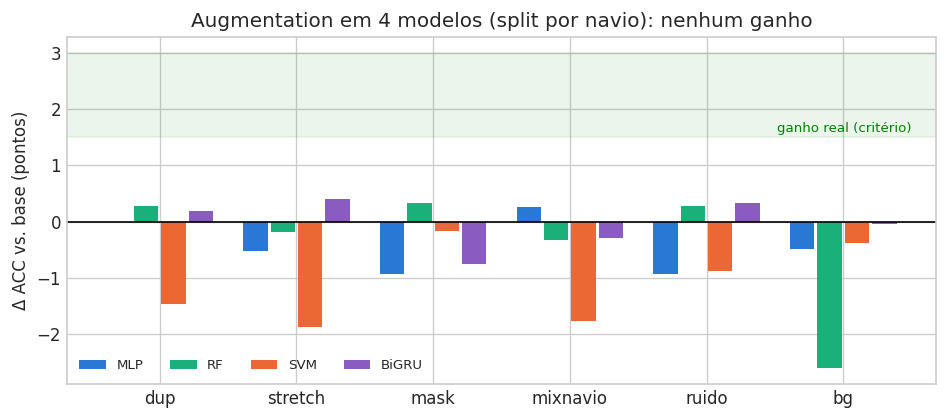

In [9]:
VS = ['base', 'dup', 'stretch', 'mask', 'mixnavio', 'ruido', 'bg']
MOD = {'MLP': 'mlp', 'RF': 'rf', 'SVM': 'svm2000', 'BiGRU': 'bigru'}
rows = []
for mn, mk in MOD.items():
    base = f'augnavio_{mk}_lofar_base_4c'; fb = R.fold_metrics(base)
    for v in VS:
        e = f'augnavio_{mk}_lofar_{v}_4c'
        try:
            fm = R.fold_metrics(e)
        except FileNotFoundError:
            continue
        dd = fm.ACC - fb.ACC
        rows.append({'modelo': mn, 'variante': v, 'ACC bal.': fm.ACC.mean(), 'SMALL': fm.R_SMALL.mean(), 'MEDIUM': fm.R_MEDIUM.mean(),
                     'BG': fm.R_BACKGROUND.mean(), 'Δ ACC': dd.mean() if v != 'base' else np.nan,
                     'p (F 5x2cv)': R.f_test_5x2(e, base, metric='ACC')[1] if v != 'base' else np.nan,
                     'folds melhores': int((dd > 0).sum()) if v != 'base' else np.nan})
MAUG = pd.DataFrame(rows).set_index(['modelo', 'variante'])
DACC = MAUG['Δ ACC'].unstack(0).reindex(VS[1:])[list(MOD)]
print('Δ acurácia balanceada vs. a base de cada modelo (pontos):'); display(DACC.round(2))
print('Valor-p (F 5x2cv, ACC):'); display(MAUG['p (F 5x2cv)'].unstack(0).reindex(VS[1:])[list(MOD)].round(3))
print('Tabela completa:'); display(MAUG.round({'ACC bal.': 1, 'SMALL': 1, 'MEDIUM': 1, 'BG': 1, 'Δ ACC': 2, 'p (F 5x2cv)': 3}))

fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.2; x = np.arange(len(DACC))
for i, (mn, c) in enumerate(zip(MOD, ['#2a78d6', '#1baf7a', '#eb6834', '#8a5cc2'])):
    ax.bar(x + (i - 1.5) * w, DACC[mn].fillna(0), w * 0.9, color=c, label=mn)
ax.axhline(0, color='k', lw=1); ax.axhspan(1.5, 3, color='green', alpha=0.08)
ax.text(len(DACC) - 0.5, 1.6, 'ganho real (critério)', fontsize=8, color='green', ha='right')
ax.set_xticks(x); ax.set_xticklabels(DACC.index); ax.set_ylabel('Δ ACC vs. base (pontos)')
ax.set_title('Augmentation em 4 modelos (split por navio): nenhum ganho'); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.**
- **Nenhum modelo melhora com nenhuma variante.** O maior ganho é 0,40 ponto (BiGRU + stretch), longe do critério de +1,5. Os ganhos pequenos têm o mesmo tamanho do controle **dup** (RF 0,28, BiGRU 0,19), ou seja, são variação do treino.
- **No SVM, as variantes trocam uma classe pela outra:** com mixnavio, SMALL cai para 20% e MEDIUM sobe para 48% (base: 39% e 33%). O modelo passa a responder "MEDIUM" mais vezes, sem separar melhor as classes.
- **O único resultado significativo é uma piora:** RF com bg, Δ -2,61 (p = 0,047), pior em todos os folds. O recall de BACKGROUND cai de 72% para 62%: com mar real dentro das gravações de navio, o RF passa a confundir mar sem navio com navio.
- **CNN do artigo:** não foi rodada (~6 h por fold, ~60 h por variante). Com o mesmo resultado em 4 modelos de famílias diferentes, é improvável que ela se comporte de outro jeito.

## 8. Navios com muitas gravações são bem reconhecidos?

Se o problema fosse falta de **gravações**, os navios muito gravados deveriam ser bem reconhecidos. A tabela separa as gravações de teste pelo número total de gravações que o navio tem no IARA, e compara os dois splits com o mesmo modelo (MLP LOFAR do NB29):
- **split por gravação:** as outras gravações do mesmo navio podem estar no treino;
- **split por navio:** o navio nunca foi visto.

In [10]:
NGR = meta[meta.Target < 2].groupby('Ship ID').size()
FAIXAS = [0, 1, 3, 9, 1000]; ROT = ['1', '2-3', '4-9', '10+']
NG, NNAV, POR_NAVIO = {}, None, {}
for cond, rot in [('split_id', 'recall, split por gravação'), ('split_navio', 'recall, split por navio')]:
    d = por_arquivo(f'{cond}_mlp_lofar_4c'); d = d[d.Target < 2].join(meta[['Ship ID', 'Name']], on='File')
    d['ngrav'] = d['Ship ID'].map(NGR); d['faixa'] = pd.cut(d.ngrav, FAIXAS, labels=ROT)
    NG[rot] = d.groupby(['Target', 'faixa'], observed=True).ok.mean() * 100
    NNAV = d.groupby(['Target', 'faixa'], observed=True)['Ship ID'].nunique()
    POR_NAVIO[rot] = d[d.ngrav >= 10].groupby(['Target', 'Name']).ok.mean() * 100
NG = pd.DataFrame(NG); NG.insert(0, 'navios', NNAV)
NG.index = NG.index.set_levels([[CN[i] for i in NG.index.levels[0]], NG.index.levels[1]])
NG.index.names = ['classe', 'gravações do navio']
print('Recall (%) pelo número de gravações que o navio tem (MLP LOFAR):'); display(NG.round(1))
POR_NAVIO = pd.DataFrame(POR_NAVIO)
POR_NAVIO['gravações'] = [int(NGR[meta[meta.Name == n]['Ship ID'].iloc[0]]) for n in POR_NAVIO.index.get_level_values(1)]
POR_NAVIO.index = POR_NAVIO.index.set_levels([[CN[i] for i in POR_NAVIO.index.levels[0]], POR_NAVIO.index.levels[1]])
print('Navios com 10 ou mais gravações:'); display(POR_NAVIO.round(0))

Recall (%) pelo número de gravações que o navio tem (MLP LOFAR):


navios  recall, split por gravação  recall, split por navio
classe gravações do navio                                                             
SMALL  1                       40                        46.0                     45.0
       2-3                     23                        60.8                     52.7
       4-9                     18                        59.1                     54.8
       10+                      6                        52.4                     47.1
MEDIUM 1                       40                        35.0                     30.0
       2-3                     16                        52.9                     36.5
       4-9                     17                        54.2                     33.5
       10+                      9                        77.4                     31.6

Navios com 10 ou mais gravações:


recall, split por gravação  recall, split por navio  gravações
Target Name                                                                             
SMALL  ENCO                                     29.0                     28.0         16
       PILOT 08                                 60.0                     52.0         68
       PILOT 09                                 60.0                     57.0         59
       PILOT 10                                 33.0                     37.0         24
       PILOT 11                                 41.0                     39.0         41
       PILOT 14                                 56.0                     47.0         87
MEDIUM C OURO                                   40.0                      9.0         13
       HANG BO 2002                             89.0                     36.0         67
       HANG BO 2003                             89.0                     36.0         79
       ILHA DA TRINDADE                         64.0                     38.0         17
       MAERSK VEGA                              76.0                     11.0         11
       NORMAND PIONEER                          76.0                     32.0         10
       NORMAND TURMALINA                        77.0                     39.0         15
       SIEM ATLAS                               38.0                     20.0         10
       SIEM GIANT                               30.0                     15.0         12

**Leitura.**
- **MEDIUM: o modelo decora o navio.** Navios MEDIUM com 10 ou mais gravações têm 77% de recall quando o navio está no treino e 32% quando não está. As dragas HANG BO chegam a 89% × 36%. Em navios nunca vistos, o recall fica parecido com qualquer número de gravações: **mais gravações do mesmo navio não ensinam a classe**.
- **SMALL: nem com o navio no treino o acerto sobe.** As lanchas de prático têm de 24 a 87 gravações cada, e mesmo assim ficam em 29–60% no split por gravação, quase igual ao split por navio. A seção 9 investiga por quê.

## 9. Lanchas de prático: por que o modelo erra mesmo conhecendo a lancha?

Usei o split por gravação, em que outras gravações da mesma lancha estão no treino. Cada gravação é testada 5 vezes (5 repetições do 5x2cv); chamo de **errada** a gravação acertada em menos da metade das vezes. Depois comparei, **dentro da mesma lancha**, as gravações erradas e as acertadas:
- **metadados e níveis:** duração, vento, nível médio do áudio, nível do fundo em 8–23 kHz (bloco mais silencioso, seção 5) e "sinal acima do fundo" (nível médio − fundo; aproximado, porque o IARA não é calibrado);
- **espectro:** LOFAR médio da gravação (dB acima do fundo TPSW, o mesmo do NB35) em 5 bandas.

Para comparar dentro da lancha, cada valor é centrado na mediana da sua lancha. AUC = chance de uma gravação errada ter valor maior que uma acertada (0,5 = não separa).

321 gravações de 15 lanchas; 146 erradas no split por gravação (errada = acertada em menos da metade das 5 vezes em que a gravação foi testada)
grupo
lancha acertada           175
lancha errada → MEDIUM     77
lancha errada → LARGE      69


,gravações,pct_erradas
Name,,
PILOT 14,87,44.0
PILOT 08,68,37.0
PILOT 09,59,41.0
PILOT 11,41,68.0
PILOT 10,24,67.0
RED I,9,33.0
PILOT 20,8,38.0
PILOT BOAT I,6,50.0


% de erradas por subconjunto: {'A': 39.0, 'B': 59.0, 'C': 40.0, 'D': 44.0}
Dentro da mesma lancha (11 lanchas com gravações acertadas e erradas; valores centrados na mediana de cada lancha):


,AUC (errada > acertada),p,Δ mediano (errada − acertada)
variável,,,
Recording time,0.5,4.1e-01,0.0e+00
vento,0.5,3.5e-01,1.0e-01
nível médio,0.5,6.4e-01,4.9e-01
fundo 8–23 kHz,0.6,2.0e-03,2.3e+00
sinal acima do fundo,0.4,0.0e+00,-3.0e+00
20–31 Hz,0.7,0.0e+00,2.6e+00
31–86 Hz,0.6,6.0e-03,8.2e-01
86–250 Hz,0.4,2.3e-02,-3.3e-01
250 Hz–1 kHz,0.3,0.0e+00,-9.3e-02


LOFAR médio (dB acima do fundo TPSW) por banda:


,gravações,20–31 Hz,31–86 Hz,86–250 Hz,250 Hz–1 kHz,1–8 kHz
lancha acertada,175,3.4,5.0,3.4,2.4,2.2
lancha errada → LARGE,69,8.0,8.6,2.5,2.3,2.1
lancha errada → MEDIUM,77,5.1,4.0,3.7,2.3,2.1
SMALL (outros tipos),155,5.1,4.8,3.3,2.4,2.2
MEDIUM,397,7.3,5.2,3.4,2.3,2.1
LARGE,572,5.4,7.5,2.7,2.4,2.2
BACKGROUND,261,3.0,3.3,4.0,2.3,2.2


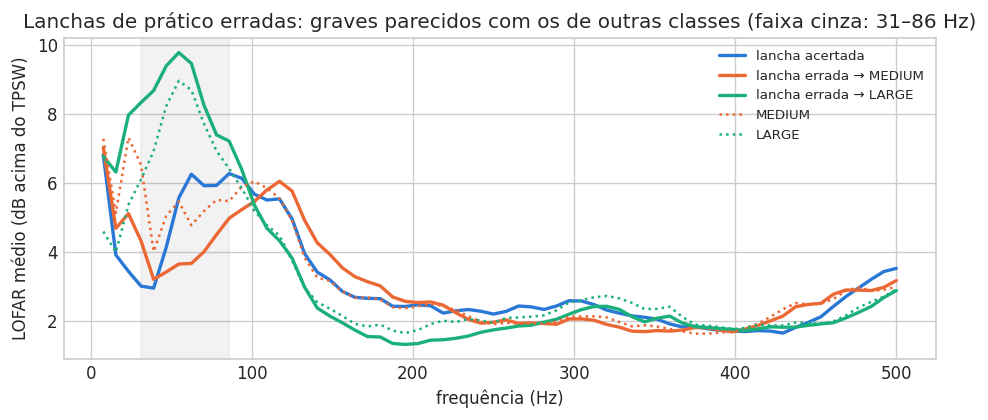

In [11]:
FQ = (np.arange(1024) + 1) * 16000 / 2048   # eixo do LOFAR do pipeline (NB35)
ESP = pd.read_pickle(os.path.join(PROC, 'cache_lofar_espectro_medio.pkl'))   # LOFAR médio por gravação, dB acima do TPSW
NIV = pd.read_pickle(os.path.join(PROC, 'cache_psd24k_niveis.pkl')); NIV.index = NIV.index.astype(int)
AMBM = pd.read_pickle(os.path.join(PROC, 'cache_amb_min_psd24k.pkl')).mean(axis=1)
d = pd.concat(R.file_predictions('split_id_mlp_lofar_4c').values()); d['File'] = d.File.astype(int)
g = d.groupby('File')
REC = pd.DataFrame({'acerto': g.apply(lambda x: (x.Prediction == x.Target).mean()),
                    'pM': g.Prediction.apply(lambda s: (s == 1).mean()), 'pL': g.Prediction.apply(lambda s: (s == 2).mean())})
LAN = meta[meta['DETAILED TYPE'] == 'Pilot Vessel'].join(REC)
LAN['errada'] = LAN.acerto < 0.5
LAN['grupo'] = np.where(~LAN.errada, 'lancha acertada', np.where(LAN.pL > LAN.pM, 'lancha errada → LARGE', 'lancha errada → MEDIUM'))
print(f"{len(LAN)} gravações de {LAN['Ship ID'].nunique()} lanchas; {int(LAN.errada.sum())} erradas no split por gravação "
      f"(errada = acertada em menos da metade das 5 vezes em que a gravação foi testada)")
print(LAN.grupo.value_counts().to_string())
LAN_NAVIO = LAN.groupby('Name').agg(gravações=('errada', 'size'), pct_erradas=('errada', 'mean')).query('gravações >= 5')
LAN_NAVIO['pct_erradas'] *= 100
display(LAN_NAVIO.sort_values('gravações', ascending=False).round(0))
LAN_SUB = LAN.groupby('Dataset').errada.mean() * 100
print('% de erradas por subconjunto:', LAN_SUB.round(0).to_dict())

# (a) dentro da mesma lancha: o que muda entre gravações erradas e acertadas?
BANDAS = {'20–31 Hz': (20, 31), '31–86 Hz': (31, 86), '86–250 Hz': (86, 250), '250 Hz–1 kHz': (250, 1000), '1–8 kHz': (1000, 8000)}
X = LAN.join(NIV[['nível médio']]).join(AMBM.rename('fundo 8–23 kHz'))
X['sinal acima do fundo'] = X['nível médio'] - X['fundo 8–23 kHz']
X['vento'] = pd.to_numeric(X.Wind, errors='coerce')
for b, (a, z) in BANDAS.items():
    X[b] = ESP.loc[X.index, (FQ >= a) & (FQ < z)].mean(axis=1).values
amb = X.groupby('Ship ID').errada.transform(lambda s: s.any() and (~s).any())
X = X[amb]
rows = []
for v in ['Recording time', 'vento', 'nível médio', 'fundo 8–23 kHz', 'sinal acima do fundo'] + list(BANDAS):
    z = X[v].astype(float) - X.groupby('Ship ID')[v].transform('median')
    a, b = z[X.errada].dropna(), z[~X.errada].dropna()
    u = st.mannwhitneyu(a, b)
    rows.append({'variável': v, 'AUC (errada > acertada)': u.statistic / (len(a) * len(b)), 'p': u.pvalue,
                 'Δ mediano (errada − acertada)': a.median() - b.median()})
LAN_AUC = pd.DataFrame(rows).set_index('variável')
LAN_N = (X['Ship ID'].nunique(), len(X))
print(f"Dentro da mesma lancha ({LAN_N[0]} lanchas com gravações acertadas e erradas; valores centrados na mediana de cada lancha):")
display(LAN_AUC.round(3))

# (b) com que classe a lancha errada se parece?
GR = {k: v.index for k, v in LAN.groupby('grupo')}
GR.update({'SMALL (outros tipos)': meta[(meta.Target == 0) & (meta['DETAILED TYPE'] != 'Pilot Vessel')].index,
           'MEDIUM': meta[meta.Target == 1].index, 'LARGE': meta[meta.Target == 2].index, 'BACKGROUND': meta[meta.Target == 3].index})
LAN_BANDA = pd.DataFrame({k: {b: ESP.loc[ESP.index.intersection(ix), (FQ >= a) & (FQ < z)].mean(axis=1).mean() for b, (a, z) in BANDAS.items()}
                          for k, ix in GR.items()}).T
LAN_BANDA.insert(0, 'gravações', [len(ESP.index.intersection(ix)) for ix in GR.values()])
print('LOFAR médio (dB acima do fundo TPSW) por banda:'); display(LAN_BANDA.round(2))

fig, ax = plt.subplots(figsize=(8, 3.6))
sel = FQ <= 500
for k, c, ls in [('lancha acertada', '#2a78d6', '-'), ('lancha errada → MEDIUM', '#eb6834', '-'), ('lancha errada → LARGE', '#1baf7a', '-'),
                 ('MEDIUM', '#eb6834', ':'), ('LARGE', '#1baf7a', ':')]:
    ax.plot(FQ[sel], ESP.loc[ESP.index.intersection(GR[k]), sel].mean().values, color=c, ls=ls, lw=2 if ls == '-' else 1.5, label=k)
ax.axvspan(31, 86, color='gray', alpha=0.1)
ax.set_xlabel('frequência (Hz)'); ax.set_ylabel('LOFAR médio (dB acima do TPSW)')
ax.set_title('Lanchas de prático erradas: graves parecidos com os de outras classes (faixa cinza: 31–86 Hz)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.**
- **Os erros vão metade para MEDIUM, metade para LARGE** (77 e 69 gravações).
- **Erradas → LARGE têm graves fortes, como os de LARGE.** Em 31–86 Hz, essas gravações ficam 8,6 dB acima do fundo, mais que a média das próprias LARGE (7,5 dB) e bem acima das lanchas acertadas (5,0 dB). É a banda que caracteriza LARGE no NB35. Cada gravação do IARA tem uma só embarcação, então esses graves não vêm de outro navio. A origem não é identificável com os dados do IARA. Hipóteses: a lancha num regime diferente (baixa rotação, parada junto ao costado) ou ruído de baixa frequência do próprio local/equipamento naquela gravação.
- **Dentro da mesma lancha, nas erradas o som próprio da lancha está mais fraco:** menos energia de 250 Hz a 8 kHz (AUC 0,29), mais graves em 20–31 Hz (AUC 0,68), fundo de 8–23 kHz mais alto e sinal acima do fundo 3,0 dB menor (AUC 0,37).
- **Condição de mar e duração não importam** (vento: AUC 0,53; duração: 0,48). O subconjunto B (perto, sem CPA) é o pior: 59% de erradas, contra 39–44% em A, C e D.
- **Resumo:** quando o modelo erra uma lancha, o som da lancha acima de 250 Hz está fraco e os graves dominam o espectro. Parte do problema de SMALL está nas gravações, não só no modelo.

## 10. A confusão SMALL × MEDIUM está nos navios perto da fronteira de 50 m?

As classes do IARA são definidas pelo comprimento (coluna `Length`): SMALL < 50 m, MEDIUM de 50 a 100 m. Se a confusão fosse física (navios de tamanho parecido soam parecido), os SMALL mais longos e os MEDIUM mais curtos seriam os mais confundidos.

Teste: split por navio (navios nunca vistos), média dos 4 modelos LOFAR base (MLP, RF, SVM, BiGRU), **um ponto por navio**.

SMALL verdadeiras (87 navios): % prevista MEDIUM por comprimento (média por navio dos 4 modelos; Spearman +0.17, p 0.11)


,navios,gravações,acerto,prevista_outra,prevista_LARGE
0–12.5 m,18,278,44.1,13.2,31.1
12.5–20 m,11,65,33.6,21.0,42.7
20–30 m,29,54,45.0,18.5,29.5
30–50 m,29,79,46.2,27.5,23.9


MEDIUM verdadeiras (82 navios): % prevista SMALL por comprimento (média por navio dos 4 modelos; Spearman +0.13, p 0.24)


,navios,gravações,acerto,prevista_outra,prevista_LARGE
50–65 m,11,38,27.8,29.5,42.4
65–75 m,17,185,29.6,43.6,25.7
75–85 m,25,90,22.7,36.9,39.5
85–100 m,29,84,29.7,43.1,24.5


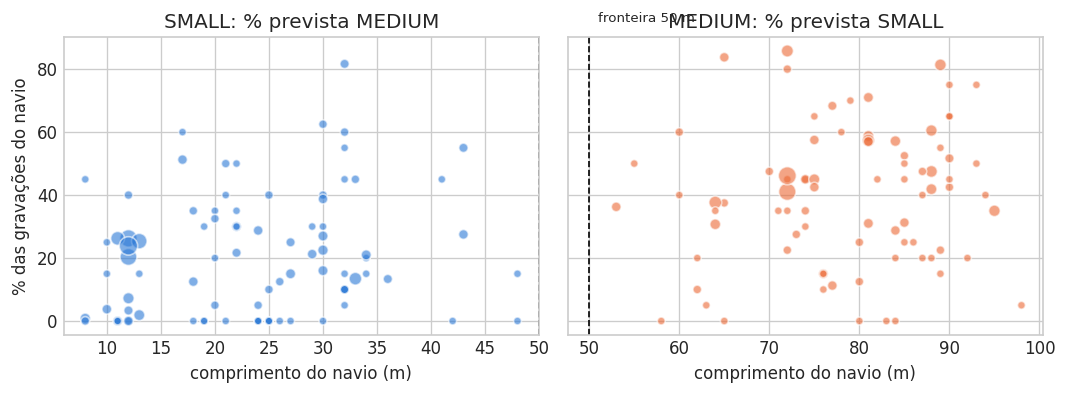

In [12]:
EXPS4 = {'MLP': 'augnavio_mlp_lofar_base_4c', 'RF': 'augnavio_rf_lofar_base_4c', 'SVM': 'augnavio_svm2000_lofar_base_4c',
         'BiGRU': 'augnavio_bigru_lofar_base_4c'}
P = pd.concat([por_arquivo(e) for e in EXPS4.values()]); P = P[P.Target < 2].join(meta[['Ship ID', 'Length']], on='File')
for c, n in [(0, 'prev_SMALL'), (1, 'prev_MEDIUM'), (2, 'prev_LARGE')]:
    P[n] = (P.Prediction == c) * 100.0
NAV = P.groupby(['Target', 'Ship ID']).agg(comprimento=('Length', 'first'), gravações=('File', 'nunique'),
                                           prev_SMALL=('prev_SMALL', 'mean'), prev_MEDIUM=('prev_MEDIUM', 'mean'),
                                           prev_LARGE=('prev_LARGE', 'mean')).reset_index()
FRONT, RHO = {}, {}
for c, outra, bins in [(0, 'prev_MEDIUM', [0, 12.5, 20, 30, 50]), (1, 'prev_SMALL', [50, 65, 75, 85, 100])]:
    s = NAV[NAV.Target == c]
    RHO[CN[c]] = st.spearmanr(s.comprimento, s[outra])
    t = s.groupby(pd.cut(s.comprimento, bins, right=False), observed=True).agg(
        navios=('Ship ID', 'size'), gravações=('gravações', 'sum'),
        acerto=('prev_SMALL' if c == 0 else 'prev_MEDIUM', 'mean'), prevista_outra=(outra, 'mean'), prevista_LARGE=('prev_LARGE', 'mean'))
    t.index = [f'{i.left:g}–{i.right:g} m' for i in t.index]
    FRONT[CN[c]] = t
    print(f"{CN[c]} verdadeiras ({len(s)} navios): % prevista {'MEDIUM' if c == 0 else 'SMALL'} por comprimento "
          f"(média por navio dos 4 modelos; Spearman {RHO[CN[c]][0]:+.2f}, p {RHO[CN[c]][1]:.2f})")
    display(t.round(1))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for a, (c, outra, cor) in zip(ax, [(0, 'prev_MEDIUM', COR['SMALL']), (1, 'prev_SMALL', COR['MEDIUM'])]):
    s = NAV[NAV.Target == c]
    a.scatter(s.comprimento, s[outra], s=10 + 12 * np.sqrt(s.gravações), color=cor, alpha=0.6, edgecolor='white')
    a.axvline(50, color='k', ls='--', lw=1)
    a.set_xlabel('comprimento do navio (m)'); a.set_title(f"{CN[c]}: % prevista {'MEDIUM' if c == 0 else 'SMALL'}")
ax[0].set_ylabel('% das gravações do navio'); ax[1].text(51, 95, 'fronteira 50 m', fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.**
- **Não há efeito de fronteira em MEDIUM:** MEDIUM de 85–100 m vai para SMALL em 43% das gravações, tanto quanto os de 65–75 m (44%); os mais curtos (50–65 m) vão **menos** para SMALL (30%). Spearman 0,13 (p = 0,245), no sentido contrário ao esperado.
- **Em SMALL há uma tendência leve, não significativa:** os de 30–50 m vão para MEDIUM em 28% das gravações, contra 13% dos de até 12,5 m (Spearman 0,17, p = 0,106).
- **Conclusão:** a confusão SMALL × MEDIUM não vem de navios de tamanho parecido. O modelo não aprendeu a relação entre tamanho e som: em navios nunca vistos, MEDIUM fica em ~27% em todas as faixas de comprimento (acaso: 25%).

## 11. Um classificador dedicado separa SMALL de MEDIUM?

Nas 4 classes, os erros para LARGE e BACKGROUND confundem a pergunta. Aqui, uma MLP h32-16 **só com SMALL e MEDIUM** (2 saídas), split por navio, com LOFAR e com DEMON, com e sem as dragas HANG BO (`scratch/apres_small_medium/small_vs_medium.py`).
- **AUC por navio:** para cada navio de teste, a média da probabilidade de MEDIUM nas suas janelas; AUC entre navios em cada repetição (cada navio é testado uma vez por repetição). 0,5 = acaso.
- **Acaso medido:** o mesmo treino com os rótulos SMALL/MEDIUM embaralhados **entre navios** (10 vezes). Com 10 repetições, o menor p possível é 1/11 ≈ 0,09.

Classificador dedicado SMALL × MEDIUM (MLP h32-16, split por navio):


recall SMALL  recall MEDIUM  acerto balanceado  AUC por navio AUC mín–máx (5 rep.) reps com p < 0,05  nulo: AUC média  nulo: máx  p permutação
LOFAR todos os navios          74.1           37.1               55.6            0.6            0.55–0.67                 3              0.5        0.5       9.0e-02
      sem HANG BO              76.5           33.0               54.8            0.6            0.60–0.68                 5              0.5        0.5       9.0e-02
DEMON todos os navios          78.7           27.4               53.0            0.5            0.42–0.51                 0              0.5        0.5       7.3e-01
      sem HANG BO              65.4           39.3               52.3            0.5            0.41–0.53                 1              0.5        0.5       5.5e-01

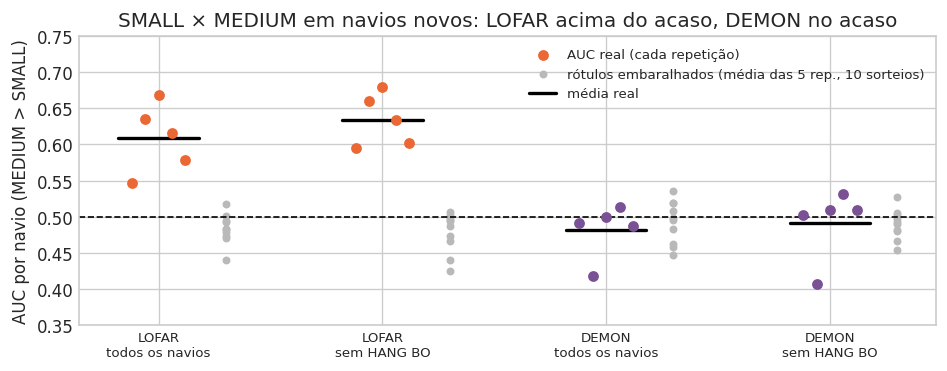

Navios por tipo (tipos com 4+ navios):


y,SMALL,MEDIUM
tipo,,
Pleasure Craft,4,0
Pilot Vessel,15,0
Fishing Vessel,22,1
Tug,34,1
Tug/Supply Vessel,0,5
Anchor Handling Vessel,0,6
Multi Purpose Offshore Vessel,0,6
Supply Vessel,0,7
Offshore Supply Ship,3,46


AUC usando SÓ o tipo do navio (fração de MEDIUM no tipo): 0.98
Dentro do mesmo tipo (escore do modelo):


,SMALL,MEDIUM,AUC,p
Offshore Supply Ship,3.0,46.0,0.6,0.5


Escore × comprimento dentro de cada classe (Spearman): {'MEDIUM': (np.float64(0.02), np.float64(0.86)), 'SMALL': (np.float64(0.15), np.float64(0.16))}


In [13]:
from scipy import stats as st
RS = os.path.join(R.ROOT, 'reports', 'small_medium')
def auc(y, s):
    u = st.mannwhitneyu(s[y == 1], s[y == 0]); return u.statistic / ((y == 1).sum() * (y == 0).sum()), u.pvalue
SXM, NUL, AUCREP = {}, {}, {}
for rep, suf in [('LOFAR', ''), ('DEMON', '_demon')]:
    res = pd.read_csv(os.path.join(RS, f'small_vs_medium{suf}_resumo.csv'))
    navsx = pd.read_csv(os.path.join(RS, f'small_vs_medium{suf}_navios.csv'), dtype={'ship': str})
    per = pd.read_csv(os.path.join(RS, f'small_vs_medium{suf}_permutacao.csv'), dtype={'ship': str})
    for var, nome in [('todos', 'todos os navios'), ('sem_hangbo', 'sem HANG BO')]:
        a = [auc(g.y.values, g.p.values) for _, g in navsx[navsx.variante == var].groupby('rep')]
        nul = per[per.variante == var].groupby(['perm', 'rep']).apply(lambda g: auc(g.y.values, g.p.values)[0]).groupby('perm').mean()
        am = np.mean([x[0] for x in a]); r = res[res.variante == var]
        AUCREP[(rep, nome)] = [x[0] for x in a]; NUL[(rep, nome)] = nul.values
        SXM[(rep, nome)] = {'recall SMALL': r.rec_SMALL.mean(), 'recall MEDIUM': r.rec_MEDIUM.mean(), 'acerto balanceado': r.bal_acc.mean(),
                            'AUC por navio': am, 'AUC mín–máx (5 rep.)': f"{min(x[0] for x in a):.2f}–{max(x[0] for x in a):.2f}",
                            'reps com p < 0,05': sum(x[1] < 0.05 for x in a), 'nulo: AUC média': nul.mean(), 'nulo: máx': nul.max(),
                            'p permutação': (1 + (nul >= am).sum()) / (1 + len(nul))}
SXM = pd.DataFrame(SXM).T
print('Classificador dedicado SMALL × MEDIUM (MLP h32-16, split por navio):')
display(SXM.assign(**{c: SXM[c].astype(float).round(2) for c in ['AUC por navio', 'nulo: AUC média', 'nulo: máx', 'p permutação']},
                   **{c: SXM[c].astype(float).round(1) for c in ['recall SMALL', 'recall MEDIUM', 'acerto balanceado']}))

fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (k, v) in enumerate(AUCREP.items()):
    ax.scatter(np.full(5, i) + np.linspace(-.12, .12, 5), v, color=COR['MEDIUM'] if k[0] == 'LOFAR' else '#7a5195', s=30, zorder=3,
               label='AUC real (cada repetição)' if i == 0 else None)
    ax.scatter(np.full(len(NUL[k]), i + .3), NUL[k], color='#b9b9b9', s=14, label='rótulos embaralhados (média das 5 rep., 10 sorteios)' if i == 0 else None)
    ax.plot([i - .18, i + .18], [np.mean(v)] * 2, color='k', lw=2, label='média real' if i == 0 else None)
ax.axhline(0.5, color='k', ls='--', lw=1)
ax.set_xticks(range(len(AUCREP))); ax.set_xticklabels([f'{a}\n{b}' for a, b in AUCREP], fontsize=8)
ax.set_ylabel('AUC por navio (MEDIUM > SMALL)'); ax.set_ylim(0.35, 0.75); ax.legend(fontsize=8, loc='upper right')
ax.set_title('SMALL × MEDIUM em navios novos: LOFAR acima do acaso, DEMON no acaso')
plt.tight_layout(); plt.show()

# tamanho ou tipo? (LOFAR, todos os navios; escore médio de cada navio nas 5 repetições)
navsx = pd.read_csv(os.path.join(RS, 'small_vs_medium_navios.csv'), dtype={'ship': str})
info_sx = meta[meta.Target < 2].groupby('Ship ID').agg(tipo=('DETAILED TYPE', 'first'), L=('Length', 'first'))
NSX = navsx[navsx.variante == 'todos'].groupby('ship').agg(y=('y', 'first'), p=('p', 'mean')).join(info_sx)
TIPOS_SXM = pd.crosstab(NSX.tipo, NSX.y.map({0: 'SMALL', 1: 'MEDIUM'}))[['SMALL', 'MEDIUM']]
TIPOS_SXM = TIPOS_SXM[TIPOS_SXM.sum(1) >= 4].sort_values('MEDIUM')
NSX['frac_tipo'] = NSX.groupby('tipo').y.transform('mean')
AUC_TIPO = auc(NSX.y.values, NSX.frac_tipo.values)[0]
DENTRO = {}
for t, g in NSX.groupby('tipo'):
    if (g.y == 0).sum() >= 3 and (g.y == 1).sum() >= 3:
        a, pv_ = auc(g.y.values, g.p.values); DENTRO[t] = {'SMALL': int((g.y == 0).sum()), 'MEDIUM': int((g.y == 1).sum()), 'AUC': a, 'p': pv_}
DENTRO = pd.DataFrame(DENTRO).T
RHO_L = {c: st.spearmanr(g.L, g.p) for c, g in NSX.groupby(NSX.y.map({0: 'SMALL', 1: 'MEDIUM'}))}
print('Navios por tipo (tipos com 4+ navios):'); display(TIPOS_SXM)
print(f'AUC usando SÓ o tipo do navio (fração de MEDIUM no tipo): {AUC_TIPO:.2f}')
print('Dentro do mesmo tipo (escore do modelo):'); display(DENTRO.astype(float).round(2))
print('Escore × comprimento dentro de cada classe (Spearman):', {k: (round(v[0], 2), round(v[1], 2)) for k, v in RHO_L.items()})

**Leitura.**
- **LOFAR: os navios são ordenados acima do acaso** (AUC 0,61; sem HANG BO 0,63), acima de todas as rodadas com rótulos embaralhados (máximo 0,52). As dragas HANG BO não explicam o sinal.
- **Mas o acerto por gravação é fraco** (55,6% balanceado): o corte entre SMALL e MEDIUM muda de fold para fold.
- **DEMON: nenhum sinal** (AUC 0,48, dentro do acaso; p de permutação 0,73).
- **Tamanho ou tipo?** No IARA, o tipo de navio quase determina a classe: usando só o tipo, a AUC seria 0,98 (SMALL = rebocadores, pesqueiros, lanchas; MEDIUM = apoio offshore). Dentro do mesmo tipo, o escore do modelo não separa SMALL de MEDIUM (Offshore Supply Ship: AUC 0,62; poucos navios de um dos lados), e dentro de cada classe ele não acompanha o comprimento (Spearman 0,15 e 0,02). **O sinal mais provável é o tipo de embarcação, não o tamanho.**

## 12. Conclusões

1. **Os modelos não generalizam MEDIUM para navios novos** (28–34%, perto do acaso). O recall de MEDIUM do artigo (~60%) vem de reconhecer navios repetidos, sobretudo as dragas HANG BO. **SMALL generaliza pouco** (~50%), sustentado pelas lanchas de prático.
2. **O que falta são navios distintos.** SMALL e MEDIUM equivalem a ~12 navios cada; o recall sobe ~11–14 pontos a cada duplicação do número de navios, sem estabilizar, e com o mesmo número de navios SMALL acerta como LARGE.
3. **Data augmentation não resolve, em nenhum modelo.** Nenhuma das variantes (inclusive a mistura com mar real) melhorou a acurácia em navios novos no MLP, RF, SVM ou BiGRU; os ganhos pequenos são do tamanho do controle "dup". Augmentation ensina o modelo a ignorar variações de condição; não cria navios novos, que é o que falta.
4. **Mais gravações do mesmo navio não ajudam.** MEDIUM com muitas gravações é decorado (HANG BO ~89% se a draga está no treino), mas isso não passa para navios novos.
5. **Em SMALL, parte do problema está nas gravações das lanchas de prático.** Mesmo conhecendo a lancha, o modelo erra 45% das gravações; nelas o som acima de 250 Hz é mais fraco e os graves dominam (origem não identificável no IARA).
6. **A confusão SMALL × MEDIUM não é física de fronteira:** um MEDIUM de 90 m é confundido com SMALL tanto quanto um de 70 m.
7. **Um classificador dedicado separa SMALL de MEDIUM só um pouco acima do acaso no LOFAR** (AUC por navio ~0,61) **e nada no DEMON**; o sinal acompanha o tipo de embarcação, que no IARA quase determina a classe, e não o comprimento.
8. **A sensibilidade ao "ambiente" existe, mas não é ruído de fundo somado.** A previsão acompanha uma assinatura da gravação em 8–23 kHz, que quase não indica a classe e não desaparece com a mistura. Hipóteses: distância, velocidade ou cadeia de gravação; o IARA não registra nenhuma delas.

**O que pode subir o SP de SMALL/MEDIUM de verdade:**
- **mais navios distintos** dessas classes (outras bases públicas, como ShipsEar e DeepShip, para pré-treino ou treino conjunto; ou novas campanhas);
- **metadados** que o IARA não publica (distância, velocidade/AIS, hidrofone), para controlar o "ambiente";
- **reformular a tarefa** (SMALL+MEDIUM juntos, regressão do comprimento ou classes por tipo de navio);
- **relatar os resultados também com split por navio**, porque o split por gravação superestima MEDIUM.